# Smart Shelf - Milestone 2, Task M2-T02: Remaining shelf-life ratio and sales velocity

**Task card:**

- `remaining_shelf_life_ratio = days_until_expiry / shelf_life_days`, clipped to [0, 1].
- `sales_velocity` = trailing 7-day `units_sold` / 7 per product-store pair, with a category-store average as fallback, computed only from sales **before** the batch's own transaction (the batch's own `units_sold` must be excluded).
- Both implemented and validated.

**What this notebook delivers**

| Output column | Status |
|---|---|
| `remaining_shelf_life_ratio` | required by the card |
| `sales_velocity` | required by the card (with two corrections, see Decisions 1 and 2) |
| `velocity_source`, `batches_in_window_7d` | support columns, so every velocity value can be traced and trusted correctly |
| `remaining_ratio_at_purchase` | extra, an alternative ratio |
| `sales_velocity_per_day` | extra, velocity in real units per day (Decision 5) |

**Decisions made in this notebook** (each one is backed by a number computed below):

1. The product-store pair is `product_name` x `store_id`, not `product_id` x `store_id`.
2. A 7-day window with no earlier batch counts as "not enough history" and uses the fallback.
3. The window stays at 7 days, as the card says.
4. The official ratio uses `days_until_expiry`, as the card says. It is not leaking.
5. An extra velocity in units per day is added next to the card's velocity.

Two findings from the validation are worth knowing before reading on: the velocities carry almost no information beyond the category (Section 6.5), and the card's velocity is not in units per day (Section 5).

## 0. Imports and loading the data

In [5]:
import os, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

In [6]:
# put the csv in the same folder as this notebook
DATA_PATH = Path("perishable_goods_management.csv")
EXPECTED_SHA = "de94302b867c9debedfd45c431306623fdfc038f5ed8ca17736339b4460a6674"   # file verified in M1-T01

sha = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("same file as verified in M1-T01:", sha == EXPECTED_SHA)

df = pd.read_csv(DATA_PATH, parse_dates=["transaction_date", "expiration_date"])
print(df.shape)
assert df.shape == (100_000, 42), "Unexpected shape"

same file as verified in M1-T01: True
(100000, 42)


## 1. Quick data checks

Only the columns used in this task are checked here. The full quality checks are in the Milestone 1 report.

In [7]:
needed = ["record_id", "product_id", "product_name", "store_id", "category", "transaction_date", "expiration_date",
          "shelf_life_days", "days_remaining_at_purchase", "days_until_expiry", "units_sold", "was_spoiled"]

print("missing columns:", [c for c in needed if c not in df.columns])
print("missing values in these columns:", int(df[needed].isna().sum().sum()))
print("duplicate rows:", df.duplicated().sum())
print("record_id is unique:", df["record_id"].is_unique)
print("shelf_life_days of 0 or below:", (df["shelf_life_days"] <= 0).sum())
print("dates from", df["transaction_date"].min().date(), "to", df["transaction_date"].max().date())
print("units_sold + units_wasted equals initial_quantity in every row:", ((df["units_sold"] + df["units_wasted"]) == df["initial_quantity"]).all())

missing columns: []
missing values in these columns: 0
duplicate rows: 0
record_id is unique: True
shelf_life_days of 0 or below: 0
dates from 2023-01-01 to 2024-12-31
units_sold + units_wasted equals initial_quantity in every row: True


## 2. Decision 1: what is a "product-store pair"?

The card says velocity is computed per product-store pair. The file has two product columns: `product_id` and `product_name`. The history of a pair only helps if the pair has **many rows**, so I count the rows per pair for both choices.

In [8]:
for product_col in ["product_id", "product_name"]:
    sizes = df.groupby([product_col, "store_id"]).size()
    print(f"{product_col:13s} x store_id -> {len(sizes):6d} pairs, rows per pair: mean {sizes.mean():5.2f}, "
          f"share of pairs with only 1 row: {(sizes == 1).mean() * 100:5.1f} %")

print()
print("distinct product_id:", df["product_id"].nunique(), "| distinct product_name:", df["product_name"].nunique())
print("rows per product_id (mean):", round(len(df) / df["product_id"].nunique(), 2))
df[["product_id", "product_name", "category"]].head(5)

product_id    x store_id ->  97984 pairs, rows per pair: mean  1.02, share of pairs with only 1 row:  98.0 %
product_name  x store_id ->   3150 pairs, rows per pair: mean 31.75, share of pairs with only 1 row:   0.0 %

distinct product_id: 45301 | distinct product_name: 63
rows per product_id (mean): 2.21


,product_id,product_name,category
0,BAK_DON_743,Donuts,Bakery
1,MEA_SAU_338,Sausages,Meat
2,BAK_BAG_799,Bagels,Bakery
3,PHA_VAC_801,Vaccines,Pharmaceuticals
4,REA_FRE_422,Fresh Pasta,Ready_to_Eat


**Decision 1: the pair is `product_name` x `store_id`.**

**Reason:** `product_id` has 45,301 distinct values (about 2 rows each) and 97,984 product-store pairs, so almost every pair has exactly one row. A pair with one row has no earlier sales, so the pair history would never exist and every velocity would come from the fallback. `product_name` has 63 values and gives 3,150 pairs with about 32 rows each, which is real history. Each `product_name` belongs to exactly one category, so the category-store fallback stays consistent.

## 3. Decision 2 and 3: how sparse is a 7-day window?

Even with `product_name` x `store_id`, a pair has about 32 rows over two years, one every 23 days. I measure how often the window is empty for different window lengths and for different groupings.

In [9]:
def empty_share(keys, days):
    d = df.sort_values(keys + ["transaction_date", "record_id"])
    n = d.groupby(keys).rolling(f"{days}D", on="transaction_date", closed="left")["units_sold"].count()
    return (n.fillna(0) == 0).mean() * 100

rows = []
for name, keys in [("product_name x store_id (the pair)", ["product_name", "store_id"]),
                   ("category x store_id (the fallback group)", ["category", "store_id"])]:
    rows.append({"group": name, **{f"{d}-day window": round(empty_share(keys, d), 1) for d in (7, 14, 28)}})
pd.DataFrame(rows).set_index("group")

,7-day window,14-day window,28-day window
group,,,
product_name x store_id (the pair),73.8,54.6,30.6
category x store_id (the fallback group),15.1,2.7,0.6


The table shows the **percentage of rows whose window contains no earlier batch at all**.

**Decision 2: an empty 7-day window means "not enough history", so the row uses the category-store fallback.**

**Reason:** about three quarters of the rows have an empty window for their own pair. If an empty window were read as velocity 0, three quarters of the feature would say "this product does not sell", which is false: it only means there is no earlier record in those 7 days. The card's rule is "fewer than 7 days of history, use the fallback", and an empty window is exactly that case.

**Decision 3: the window stays at 7 days.**

**Reason:** the card defines it. Widening to 14 or 28 days still leaves 55% and 31% of the windows empty, so a longer window would not solve the problem. The fallback does, and it covers every row except the very first ones.

## 4. Feature 1: remaining shelf-life ratio

It tells how much of the shelf life is still left. `5 days left` means "almost expired" for a product that lasts 14 days, but "just started" for one that lasts 6 days, and "almost nothing" for one that lasts 180. Dividing by the shelf life puts every product on the same 0 to 1 scale: near 1 is fresh, near 0 is close to the end.

The formula in the card, `(shelf_life_days - (shelf_life_days - days_until_expiry)) / shelf_life_days`, simplifies to `days_until_expiry / shelf_life_days`. I check that.

A shelf life of 0 would divide by zero, and clipping infinity gives 1 ("fresh") with no warning. So a shelf life of 0 or below is set to empty first. In this file there are none, but the guard stays.

In [10]:
shelf = df["shelf_life_days"].where(df["shelf_life_days"] > 0)
raw_ratio = df["days_until_expiry"] / shelf

print("rows with no valid ratio:", raw_ratio.isna().sum())
print("below 0 before clipping:", (raw_ratio < 0).sum())
print("above 1 before clipping:", (raw_ratio > 1).sum())

df["remaining_shelf_life_ratio"] = raw_ratio.clip(0, 1)

long_formula = ((shelf - (shelf - df["days_until_expiry"])) / shelf).clip(0, 1)
print("same as the card's long formula:", np.allclose(long_formula, df["remaining_shelf_life_ratio"], equal_nan=True))
df["remaining_shelf_life_ratio"].describe().round(3)

rows with no valid ratio: 0
below 0 before clipping: 0
above 1 before clipping: 0
same as the card's long formula: True


count    100000.000
mean          0.640
std           0.279
min           0.000
25%           0.500
50%           0.709
75%           0.833
max           1.000
Name: remaining_shelf_life_ratio, dtype: float64

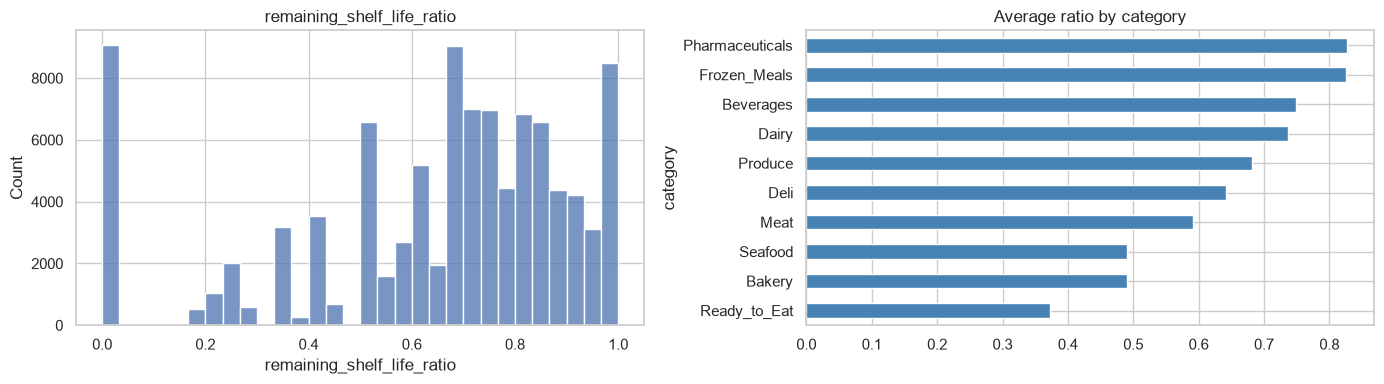

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["remaining_shelf_life_ratio"], bins=30, ax=axes[0])
axes[0].set_title("remaining_shelf_life_ratio")

df.groupby("category")["remaining_shelf_life_ratio"].mean().sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Average ratio by category")

plt.tight_layout()
plt.savefig("figures/m2_t02_remaining_ratio.png", dpi=150, bbox_inches="tight")
plt.show()

### Decision 4: which "days left" column is the official one?

The Milestone 1 report found that `days_until_expiry` is 0 to 3 days lower than the date gap in 74,191 rows, and that its origin is unknown. The card uses it. Before keeping it, I test whether it could leak the outcome. If it were measured after the batch spoiled, the size of the lag would be related to `was_spoiled`.

In [12]:
df["expiry_lag_days"] = df["days_remaining_at_purchase"] - df["days_until_expiry"]
gap = (df["expiration_date"] - df["transaction_date"]).dt.days

print("days_remaining_at_purchase differs from the date gap in", (gap != df["days_remaining_at_purchase"]).sum(), "rows")
print("days_until_expiry differs from the date gap in", (gap != df["days_until_expiry"]).sum(), "rows")
print("lag values (days):", df["expiry_lag_days"].value_counts().sort_index().to_dict())
print()

# is the lag different for spoiled and not spoiled batches?
check = df.groupby("was_spoiled")["expiry_lag_days"].agg(mean="mean", share_with_lag=lambda s: (s > 0).mean())
print(check.round(3))

# the lag compared with other things known about the batch
print()
for col in ["distribution_hours", "handling_score", "temp_abuse_events", "supplier_score"]:
    print(f"correlation of the lag with {col:20s}: {df['expiry_lag_days'].corr(df[col]):+.3f}")

days_remaining_at_purchase differs from the date gap in 0 rows
days_until_expiry differs from the date gap in 74191 rows
lag values (days): {0: 25809, 1: 26492, 2: 25614, 3: 22085}

              mean  share_with_lag
was_spoiled                       
0            1.444           0.743
1            1.423           0.736

correlation of the lag with distribution_hours  : +0.004
correlation of the lag with handling_score      : -0.004
correlation of the lag with temp_abuse_events   : -0.003
correlation of the lag with supplier_score      : +0.003


In [13]:
# does either ratio 'know' the outcome on its own? (AUC: 0.5 = no signal, direction ignored in the last column)
df["remaining_ratio_at_purchase"] = (df["days_remaining_at_purchase"] / shelf).clip(0, 1)

rows = []
for col in ["remaining_shelf_life_ratio", "remaining_ratio_at_purchase"]:
    auc = roc_auc_score(df["was_spoiled"], df[col])
    rows.append({"ratio": col, "mean if spoiled": df.loc[df["was_spoiled"] == 1, col].mean(),
                 "mean if not spoiled": df.loc[df["was_spoiled"] == 0, col].mean(),
                 "AUC": auc, "strength (0 = none)": abs(auc - 0.5) * 2})
pd.DataFrame(rows).round(3)

,ratio,mean if spoiled,mean if not spoiled,AUC,strength (0 = none)
0,remaining_shelf_life_ratio,0.624,0.644,0.481,0.039
1,remaining_ratio_at_purchase,0.824,0.841,0.474,0.052


**Decision 4: the official `remaining_shelf_life_ratio` uses `days_until_expiry`, exactly as the card says.**

**Reason:** there is no sign that it leaks the outcome. The lag is 0 to 3 days with about the same spread for spoiled and not spoiled batches (about 74% of both groups have a lag), and it has essentially no correlation with distribution hours, handling, temperature abuse events or supplier score. A column that was measured after spoilage would show a different lag for spoiled batches. This also matches `expiry_remaining_ratio`, built from the same column in the M1-T04 preprocessing, so the feature is consistent with the cleaned dataset.

`remaining_ratio_at_purchase` (built from the column that matches the date gap exactly) is kept as an extra column. Both ratios are weak, with AUC slightly below 0.5 (a fresher batch is slightly less likely to spoil): strength 0.04 for the card's ratio and 0.05 for the extra one. The extra costs nothing and gives Milestone 3 a second version to test.

## 5. Feature 2: sales velocity

Sales velocity is how fast a product sells in a store. A slow seller is more likely to still be on the shelf when it expires.

**The rule**, with the decisions above applied:

1. For each batch, take the earlier batches of the same `product_name` in the same store whose transaction date falls in the 7 days before this batch (days `t-7` to `t-1`). Add up their `units_sold` and divide by 7.
2. The batch's own `units_sold` and other batches of the same day are not counted. The own value is only known after the sale, so using it would leak the answer. "Before" means earlier days only, because the order of batches inside one day is unknown.
3. If the pair has fewer than 7 days of history, **or** the window contains no earlier batch (Decision 2), use the **category-store average**: units sold in earlier days for that category in that store, divided by the days since its first record (at least 7).
4. If there is no earlier data at all (the first days of the file), the velocity stays empty. It is not set to 0, because 0 would claim the product does not sell. These rows are marked `no_history`.

**Support columns:** `velocity_source` says which rule produced the value, and `batches_in_window_7d` says how many earlier batches the value is based on.

### The extra: `sales_velocity_per_day` (Decision 5)

In this file `units_sold` is the **total** sold from a batch over its whole shelf life (`units_sold + units_wasted = initial_quantity` in every row). A batch of frozen meals sells 137 units over about 200 days, while a batch of ready-to-eat food sells 220 units in 3 days. The card's velocity adds up batch totals and divides by 7, so it mixes these very different time scales, and it is **not** a number of units per day.

A units-per-day number is what a "days to sell out" calculation (stock divided by velocity) needs. So I add a second velocity: for each earlier batch, `units_sold / days_remaining_at_purchase` (the days the batch had to sell), then the average of those rates in the same window, with the same fallback and the same leakage rules.

In [14]:
PAIR = ["product_name", "store_id"]      # Decision 1
WINDOW = 7                               # Decision 3

def add_sales_velocity(data):
    # sort so that every product-store pair is in date order
    data = data.sort_values(PAIR + ["transaction_date", "record_id"]).reset_index(drop=True)

    # units per day of each batch over its own selling period (used for the extra velocity)
    data["batch_rate"] = data["units_sold"] / data["days_remaining_at_purchase"].clip(lower=1)

    # step 1: earlier batches of the same pair inside the window
    # closed="left" leaves the current day out, so the row's own units_sold is never counted
    roller = data.groupby(PAIR).rolling(f"{WINDOW}D", on="transaction_date", closed="left")
    sold = roller["units_sold"].sum()
    rate_sum = roller["batch_rate"].sum()
    batches = roller["units_sold"].count()

    # the groups come out in the same order as the sorted table, so the values can be put straight back
    # (this check makes sure that really is true)
    assert (sold.index.get_level_values("transaction_date") == data["transaction_date"].values).all()
    data["sold_last_7d"] = sold.fillna(0).values
    data["batches_in_window_7d"] = batches.fillna(0).astype(int).values
    window_rate = (rate_sum / batches).values                     # average rate of the batches in the window (NaN if none)

    # step 2: how many days of history does this pair have so far?
    first_date = data.groupby(PAIR)["transaction_date"].transform("min")
    data["pair_history_days"] = (data["transaction_date"] - first_date).dt.days

    # step 3: fallback = same category in the same store, earlier days only
    daily = (data.groupby(["category", "store_id", "transaction_date"])
                 .agg(units=("units_sold", "sum"), rates=("batch_rate", "sum"), n=("batch_rate", "size")).reset_index())
    daily = daily.sort_values(["category", "store_id", "transaction_date"])
    by_group = daily.groupby(["category", "store_id"])
    units_before = by_group["units"].cumsum() - daily["units"]       # everything sold on earlier days
    rates_before = by_group["rates"].cumsum() - daily["rates"]
    batches_before = by_group["n"].cumsum() - daily["n"]
    history_days = (daily["transaction_date"] - by_group["transaction_date"].transform("min")).dt.days
    daily["cat_store_velocity"] = units_before / history_days.clip(lower=7)
    daily["cat_store_rate"] = rates_before / batches_before.replace(0, np.nan)
    daily.loc[history_days == 0, ["cat_store_velocity", "cat_store_rate"]] = np.nan     # nothing earlier at all

    n_before = len(data)
    data = data.merge(daily[["category", "store_id", "transaction_date", "cat_store_velocity", "cat_store_rate"]],
                      on=["category", "store_id", "transaction_date"], how="left")
    assert len(data) == n_before          # the merge must not add or remove rows

    # step 4: own window if the pair has 7+ days of history AND at least one earlier batch in the window
    use_own = (data["pair_history_days"] >= WINDOW) & (data["batches_in_window_7d"] > 0)
    data["sales_velocity"] = np.where(use_own, data["sold_last_7d"] / WINDOW, data["cat_store_velocity"])
    data["sales_velocity_per_day"] = np.where(use_own, window_rate, data["cat_store_rate"])
    data["velocity_source"] = np.where(use_own, "product_store_7d",
                              np.where(data["cat_store_velocity"].notna(), "category_store_avg", "no_history"))
    return data

In [15]:
features = add_sales_velocity(df)
print(features.shape)
features[["record_id", "product_name", "store_id", "transaction_date", "units_sold", "sold_last_7d",
          "batches_in_window_7d", "pair_history_days", "sales_velocity", "sales_velocity_per_day",
          "velocity_source"]].head(10)

(100000, 54)


,record_id,product_name,store_id,transaction_date,units_sold,sold_last_7d,batches_in_window_7d,pair_history_days,sales_velocity,sales_velocity_per_day,velocity_source
0,32376,Antibiotics,STORE_001,2023-01-02,298,0.0,0,0,48.428571,0.424486,category_store_avg
1,53379,Antibiotics,STORE_001,2023-02-05,51,0.0,0,34,36.085714,0.526783,category_store_avg
2,18356,Antibiotics,STORE_001,2023-02-07,0,51.0,1,36,7.285714,0.369565,product_store_7d
3,7450,Antibiotics,STORE_001,2023-02-23,16,0.0,0,52,43.566038,0.542303,category_store_avg
4,90801,Antibiotics,STORE_001,2023-05-21,0,0.0,0,139,27.042857,0.494561,category_store_avg
5,44891,Antibiotics,STORE_001,2023-06-12,133,0.0,0,161,28.691358,0.823873,category_store_avg
6,439,Antibiotics,STORE_001,2023-06-14,30,133.0,1,163,19.000000,0.245841,product_store_7d
7,27620,Antibiotics,STORE_001,2023-07-03,74,0.0,0,182,28.289617,0.733074,category_store_avg
8,98846,Antibiotics,STORE_001,2023-08-16,0,0.0,0,226,31.762115,0.874274,category_store_avg
9,90107,Antibiotics,STORE_001,2023-09-08,0,0.0,0,249,32.492000,0.832120,category_store_avg


`sold_last_7d` is the sum of earlier sales in the window, `batches_in_window_7d` is how many batches it comes from, `pair_history_days` is how long the pair has been in the data, `sales_velocity` is the card's feature and `sales_velocity_per_day` is the extra.

In [16]:
counts = features["velocity_source"].value_counts()
print(counts)
print()
print((counts / len(features) * 100).round(1).astype(str) + " %")

own = features[features["velocity_source"] == "product_store_7d"]
print()
print("rows that use their own window:", len(own))
print("  of those, with exactly 1 earlier batch in the window:", round((own["batches_in_window_7d"] == 1).mean() * 100, 1), "%")
print("  of those, with velocity exactly 0 (batches that sold nothing):", round((own["sales_velocity"] == 0).mean() * 100, 1), "%")
print()
features[["sales_velocity", "sales_velocity_per_day"]].describe().round(2)

velocity_source
category_store_avg    74009
product_store_7d      25415
no_history              576
Name: count, dtype: int64

velocity_source
category_store_avg    74.0 %
product_store_7d      25.4 %
no_history             0.6 %
Name: count, dtype: str

rows that use their own window: 25415
  of those, with exactly 1 earlier batch in the window: 85.0 %
  of those, with velocity exactly 0 (batches that sold nothing): 7.7 %



,sales_velocity,sales_velocity_per_day
count,99424.00,99424.00
mean,50.71,42.08
std,19.99,45.02
min,0.00,0.00
25%,40.33,12.60
50%,54.82,30.30
75%,62.58,66.54
max,236.43,500.00


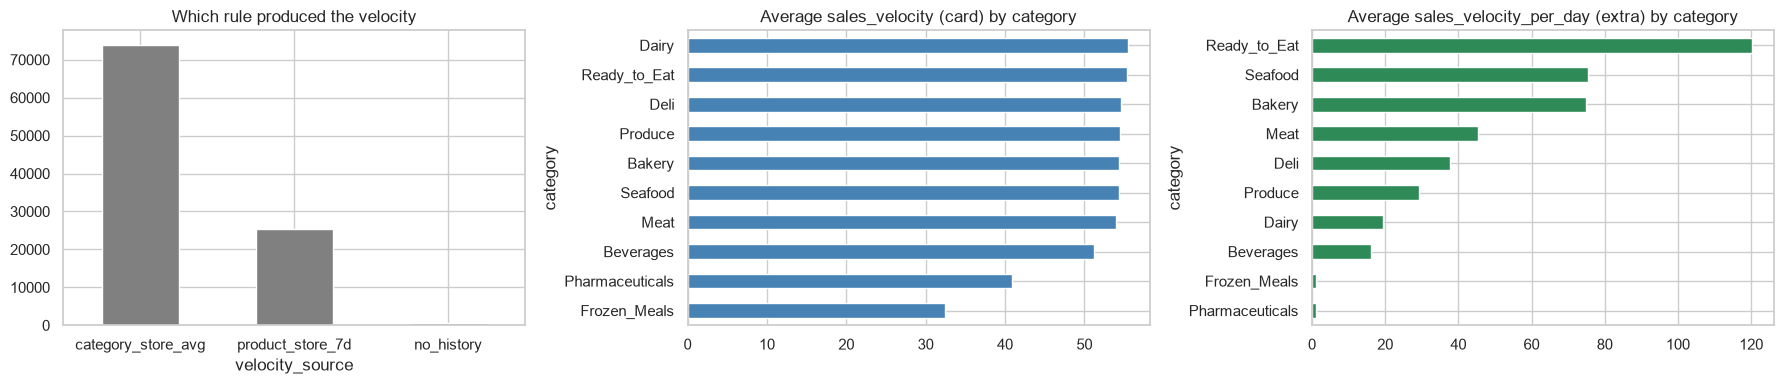

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

counts.plot(kind="bar", ax=axes[0], color="grey", rot=0)
axes[0].set_title("Which rule produced the velocity")

features.groupby("category")["sales_velocity"].mean().sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Average sales_velocity (card) by category")

features.groupby("category")["sales_velocity_per_day"].mean().sort_values().plot(kind="barh", ax=axes[2], color="seagreen")
axes[2].set_title("Average sales_velocity_per_day (extra) by category")

plt.tight_layout()
plt.savefig("figures/m2_t02_sales_velocity.png", dpi=150, bbox_inches="tight")
plt.show()

### Why the extra velocity is needed (Decision 5)

The two velocities are compared with `daily_demand`, a column that is already in the file and is measured in units per day, and with `shelf_life_days`.

In [18]:
# batch totals and shelf lives are very different between categories
features.groupby("category")[["units_sold", "shelf_life_days", "daily_demand"]].mean().round(1).sort_values("shelf_life_days")

,units_sold,shelf_life_days,daily_demand
category,,,
Ready_to_Eat,220.3,3.0,186.4
Bakery,216.9,4.5,114.3
Seafood,212.8,4.5,108.8
Meat,214.0,6.5,73.3
Deli,219.3,8.5,59.4
Produce,215.4,12.0,44.8
Dairy,220.5,17.5,29.4
Beverages,211.1,18.5,24.1
Frozen_Meals,137.0,212.3,1.6


In [19]:
batch_level = features["units_sold"] / features["days_remaining_at_purchase"].clip(lower=1)
print("batch level: corr(units_sold / selling days, daily_demand) =", round(batch_level.corr(features["daily_demand"]), 3))
print("batch level: corr(units_sold, daily_demand)                =", round(features["units_sold"].corr(features["daily_demand"]), 3))
print()
table = pd.DataFrame({
    "corr with shelf_life_days": [features["sales_velocity"].corr(features["shelf_life_days"]),
                                  features["sales_velocity_per_day"].corr(features["shelf_life_days"])],
    "corr with daily_demand": [features["sales_velocity"].corr(features["daily_demand"]),
                               features["sales_velocity_per_day"].corr(features["daily_demand"])],
}, index=["sales_velocity (card)", "sales_velocity_per_day (extra)"])
table.round(3)

batch level: corr(units_sold / selling days, daily_demand) = 0.918
batch level: corr(units_sold, daily_demand)                = 0.44



,corr with shelf_life_days,corr with daily_demand
sales_velocity (card),-0.264,0.132
sales_velocity_per_day (extra),-0.395,0.479


**Decision 5: keep both. `sales_velocity` is the card's feature. `sales_velocity_per_day` is the one to use wherever a number of units per day is needed.**

**Reason:** at batch level, `units_sold / selling days` follows `daily_demand` closely, while the raw `units_sold` does not, so dividing by the selling days is what turns a batch total into a daily speed. The card's velocity is tied to shelf life (long-life products have large batch totals spread over many days). 

**An honest finding:** both velocities are mostly a category signal in this file. Inside a category, the velocity of earlier batches has almost no relation to the next batch (correlation 0.007, Section 6.5b), and neither velocity predicts spoilage on its own (Section 6.5c).

## 6. Validation

"Implemented **and validated**" means proving the code is right, so the features are tested in several ways.

### 6.1 Remaining shelf-life ratio

In [20]:
r = features["remaining_shelf_life_ratio"]
print("missing values:", r.isna().sum())
print("smallest:", r.min(), " largest:", r.max())
assert r.min() >= 0 and r.max() <= 1

# 5 rows calculated by hand
check = features[["shelf_life_days", "days_until_expiry", "remaining_shelf_life_ratio"]].sample(5, random_state=1).copy()
check["by_hand"] = (check["days_until_expiry"] / check["shelf_life_days"]).clip(0, 1)
check

missing values: 0
smallest: 0.0  largest: 1.0


,shelf_life_days,days_until_expiry,remaining_shelf_life_ratio,by_hand
43660,6,3,0.500000,0.500000
87278,4,0,0.000000,0.000000
14317,18,13,0.722222,0.722222
81932,22,21,0.954545,0.954545
95321,89,67,0.752809,0.752809


### 6.2 Sales velocity: recalculate it the slow way

300 random rows are recalculated with a plain loop that follows the rules word for word. If the fast pandas code and the slow loop agree on every row, the fast code is right. The loop checks the card's velocity, the per-day velocity and the batch count.

In [21]:
sample = features[features["velocity_source"] == "product_store_7d"].sample(300, random_state=0)

wrong = 0
for i, row in sample.iterrows():
    same_pair = features[(features["product_name"] == row["product_name"]) & (features["store_id"] == row["store_id"])]
    start = row["transaction_date"] - pd.Timedelta(days=WINDOW)
    in_window = same_pair[(same_pair["transaction_date"] >= start) & (same_pair["transaction_date"] < row["transaction_date"])]

    expected_velocity = in_window["units_sold"].sum() / WINDOW
    expected_per_day = (in_window["units_sold"] / in_window["days_remaining_at_purchase"].clip(lower=1)).mean()

    if (abs(expected_velocity - row["sales_velocity"]) > 1e-9
            or abs(expected_per_day - row["sales_velocity_per_day"]) > 1e-9
            or len(in_window) != row["batches_in_window_7d"]):
        wrong += 1

print("rows checked:", len(sample), "| rows that do not match:", wrong)

rows checked: 300 | rows that do not match: 0


In [22]:
# the same for rows that used the category-store fallback
fallback_rows = features[features["velocity_source"] == "category_store_avg"]
sample = fallback_rows.sample(300, random_state=0)

wrong = 0
for i, row in sample.iterrows():
    same_group = features[(features["category"] == row["category"]) & (features["store_id"] == row["store_id"])]
    earlier = same_group[same_group["transaction_date"] < row["transaction_date"]]
    days = max((row["transaction_date"] - same_group["transaction_date"].min()).days, 7)

    expected_velocity = earlier["units_sold"].sum() / days
    expected_per_day = (earlier["units_sold"] / earlier["days_remaining_at_purchase"].clip(lower=1)).mean()

    if abs(expected_velocity - row["sales_velocity"]) > 1e-9 or abs(expected_per_day - row["sales_velocity_per_day"]) > 1e-9:
        wrong += 1

print("rows checked:", len(sample), "| rows that do not match:", wrong)

rows checked: 300 | rows that do not match: 0


### 6.3 Sales velocity: the leakage test

If the batch's own `units_sold` is really excluded, then changing it must **not** change that batch's own velocity.

1. Pick one batch from every category-store group and set its `units_sold` to 1,000,000.
2. Recompute both velocities.
3. The velocities of the changed batches must stay exactly the same, because they only use earlier rows. Later batches may change, since they do use earlier sales. If none changed, the test would prove nothing, so that is checked too.

In [23]:
cols = ["record_id", "product_name", "store_id", "category", "transaction_date", "units_sold", "days_remaining_at_purchase"]
original = df[cols].copy()

changed_ids = original.groupby(["category", "store_id"]).sample(1, random_state=0)["record_id"]

altered = original.copy()
altered.loc[altered["record_id"].isin(changed_ids), "units_sold"] = 1_000_000

before = add_sales_velocity(original).set_index("record_id")
after = add_sales_velocity(altered).set_index("record_id").loc[before.index]

is_changed_row = before.index.isin(changed_ids)
for col in ["sales_velocity", "sales_velocity_per_day"]:
    same = np.isclose(before[col], after[col], equal_nan=True)
    print(f"{col}: changed batches whose own value changed (must be 0): {(~same[is_changed_row]).sum()}"
          f" | other batches that changed (should be more than 0): {(~same[~is_changed_row]).sum()}")

sales_velocity: changed batches whose own value changed (must be 0): 0 | other batches that changed (should be more than 0): 35561
sales_velocity_per_day: changed batches whose own value changed (must be 0): 0 | other batches that changed (should be more than 0): 35561


### 6.4 Final checks

In [24]:
long_history = features["pair_history_days"] >= WINDOW
has_batches = features["batches_in_window_7d"] > 0
own_rows = features["velocity_source"] == "product_store_7d"

print("own window used although history < 7 days or window empty:", (own_rows & ~(long_history & has_batches)).sum())
print("fallback used although own window was possible:", (~own_rows & (long_history & has_batches)).sum())
print("negative velocities:", (features["sales_velocity"] < 0).sum(), "| negative per-day velocities:", (features["sales_velocity_per_day"] < 0).sum())
print("rows with no velocity (no_history):", features["sales_velocity"].isna().sum(),
      "| same rows for the per-day version:", features["sales_velocity_per_day"].isna().sum())
print("rows in df:", len(df), "| rows in features:", len(features), "| record_id unique:", features["record_id"].is_unique)

own window used although history < 7 days or window empty: 0
fallback used although own window was possible: 0
negative velocities: 0 | negative per-day velocities: 0
rows with no velocity (no_history): 576 | same rows for the per-day version: 576
rows in df: 100000 | rows in features: 100000 | record_id unique: True


### 6.5 Two checks that show what the velocity can and cannot do

**(a) How much of the velocity comes from batches that were still on the shelf?** Because `units_sold` is a batch's final total, an earlier batch that had not expired yet on day `t` had not finished selling. The card's rule counts it anyway. This measures how much that affects the feature, so the limitation is a number and not a guess.

In [25]:
groups = {key: g for key, g in features.groupby(PAIR)}
sample = features[features["velocity_source"] == "product_store_7d"].sample(3000, random_state=0)

shares = []
for i, row in sample.iterrows():
    g = groups[(row["product_name"], row["store_id"])]
    start = row["transaction_date"] - pd.Timedelta(days=WINDOW)
    in_window = g[(g["transaction_date"] >= start) & (g["transaction_date"] < row["transaction_date"])]
    unfinished = in_window["expiration_date"] >= row["transaction_date"]          # still on the shelf on day t
    total = in_window["units_sold"].sum()
    if total > 0:
        shares.append(in_window.loc[unfinished, "units_sold"].sum() / total)

shares = pd.Series(shares)
print("rows checked:", len(shares))
print("average share of window sales that come from batches still on the shelf:", round(shares.mean() * 100, 1), "%")
print("rows where ALL of the window sales come from unfinished batches:", round((shares == 1).mean() * 100, 1), "%")

rows checked: 2786
average share of window sales that come from batches still on the shelf: 78.3 %
rows where ALL of the window sales come from unfinished batches: 76.6 %


**(b) Does that matter?** It matters only if earlier batches carry information about the *current* batch beyond what the category already says. The test: inside each category, how strongly does the velocity of a batch correlate with that batch's own selling speed (`units_sold / days_remaining_at_purchase`, the thing it must not know)? Subtracting the category average removes the category signal. A value near 0 means nothing about the current batch passes through the earlier batches.

In [26]:
test = features[features["velocity_source"] == "product_store_7d"].copy()
test["own_rate"] = test["units_sold"] / test["days_remaining_at_purchase"].clip(lower=1)

def minus_category_mean(col):
    return test[col] - test.groupby("category")[col].transform("mean")

print("inside categories, own selling speed vs sales_velocity_per_day of earlier batches:",
      round(minus_category_mean("own_rate").corr(minus_category_mean("sales_velocity_per_day")), 3))
print("inside categories, own units_sold vs sales_velocity of earlier batches:",
      round(minus_category_mean("units_sold").corr(minus_category_mean("sales_velocity")), 3))
print("(for comparison, across all rows, own selling speed vs sales_velocity_per_day:",
      round(test["own_rate"].corr(test["sales_velocity_per_day"]), 3), ")")

inside categories, own selling speed vs sales_velocity_per_day of earlier batches: 0.007
inside categories, own units_sold vs sales_velocity of earlier batches: 0.002
(for comparison, across all rows, own selling speed vs sales_velocity_per_day: 0.343 )


**(c) Do the velocities say anything about spoilage on their own?** AUC of each velocity against `was_spoiled` (0.5 = no signal).

In [27]:
y = features["was_spoiled"]
rows = []
for col in ["sales_velocity", "sales_velocity_per_day", "remaining_shelf_life_ratio", "remaining_ratio_at_purchase"]:
    ok = features[col].notna()
    auc = roc_auc_score(y[ok], features.loc[ok, col])
    rows.append({"feature": col, "AUC vs was_spoiled": auc})
pd.DataFrame(rows).round(3)

,feature,AUC vs was_spoiled
0,sales_velocity,0.503
1,sales_velocity_per_day,0.513
2,remaining_shelf_life_ratio,0.481
3,remaining_ratio_at_purchase,0.474


**What the validation shows (real file, SHA-256 verified):**

- The recalculation matches the code on every sampled row, the leakage test passes for both velocities, and every row is accounted for.
- About 78% of the sales in a window come from batches that were still on the shelf on day `t` (6.5a). This looks like a leakage risk, but the test in 6.5b shows it is harmless here: inside a category the velocity has essentially no relation to the current batch (correlation 0.007 and 0.002), so no information about the current batch passes through the earlier ones. In a real deployment only finished batches should be counted.
- The velocities do not predict spoilage on their own (AUC 0.503 and 0.513), like most single inputs in this dataset (M1 report: all effects are weak). Their value is for the sell-through ratio and the revenue and waste side of Milestone 3, not as a strong stand-alone spoilage predictor.

## 7. Save the new columns

In [28]:
out = features[["record_id", "remaining_shelf_life_ratio", "remaining_ratio_at_purchase", "sales_velocity",
                "sales_velocity_per_day", "velocity_source", "batches_in_window_7d"]]
out = out.sort_values("record_id")
out.to_csv("m2_t02_features.csv", index=False)
print(out.shape)
out.head()

(100000, 7)


,record_id,remaining_shelf_life_ratio,remaining_ratio_at_purchase,sales_velocity,sales_velocity_per_day,velocity_source,batches_in_window_7d
31290,1,0.500000,1.000000,66.302694,76.009651,category_store_avg,0
79099,2,0.444444,0.777778,56.841584,39.523878,category_store_avg,0
5628,3,0.000000,1.000000,115.714286,128.488889,product_store_7d,3
95297,4,0.908046,0.919540,57.737952,0.839433,category_store_avg,0
36435,5,0.750000,0.750000,60.469484,108.678056,category_store_avg,0


The file is saved next to the notebook. `.gitignore` ignores `*.csv`, so it stays on the local machine. It joins to the cleaned dataset on `record_id`, and the notebook recreates it in about a minute.

## 8. Text for the Feature Engineering Summary

| Feature | Formula | Columns used | Notes |
|---|---|---|---|
| `remaining_shelf_life_ratio` | `days_until_expiry / shelf_life_days`, clipped to [0, 1]; empty if `shelf_life_days` <= 0 | `days_until_expiry`, `shelf_life_days` | Near 0: close to or past expected life. Near 1: fresh. Puts products with different shelf lives on one scale. Checked for leakage (the 0-3 day lag against `days_remaining_at_purchase` is unrelated to `was_spoiled`). Equals `expiry_remaining_ratio` from M1-T04. |
| `remaining_ratio_at_purchase` (extra) | `days_remaining_at_purchase / shelf_life_days`, clipped to [0, 1] | `days_remaining_at_purchase`, `shelf_life_days` | Same idea with the column that matches the date gap exactly. |
| `sales_velocity` | sum of `units_sold` of earlier batches of the same `product_name` in the same store in the 7 days before the batch, divided by 7 | `units_sold`, `product_name`, `store_id`, `transaction_date` | Earlier days only, so the batch's own `units_sold` is excluded. The pair uses `product_name` because `product_id` gives about one row per pair. |
| `sales_velocity` (fallback) | units sold in earlier days in the same category and store, divided by the days since the first record of that group (at least 7) | `units_sold`, `category`, `store_id`, `transaction_date` | Used when the pair has less than 7 days of history or no earlier batch in the window (about three quarters of the rows). |
| `sales_velocity_per_day` (extra) | average of `units_sold / days_remaining_at_purchase` over the same earlier batches, with the same fallback | `units_sold`, `days_remaining_at_purchase`, ... | Real units per day. Use it for stock / velocity calculations. |
| `velocity_source` | `product_store_7d`, `category_store_avg` or `no_history` | | Shows which rule produced the value. `no_history` rows have an empty velocity. |
| `batches_in_window_7d` | number of earlier batches in the 7-day window | `product_name`, `store_id`, `transaction_date` | How many batches the value is based on. |

Validation: 300-row recalculation for both rules, a leakage test that changes the own `units_sold`, and consistency checks. Limitation: `units_sold` is a batch's final total, so about 78% of each window's sales come from batches that had not finished selling on day `t` (Section 6.5a). The test in Section 6.5b shows no information about the current batch passes through them (within-category correlation 0.007), so it does not distort this dataset. In deployment, count only finished batches.